In [1]:
!nvidia-smi

Mon Oct  5 00:53:49 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
!apt-get update -qq
!apt-get install -y -qq colmap
!colmap -h | head -20

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Extracting templates from packages: 100%
Selecting previously unselected package libevdev2:amd64.
(Reading database ... 127332 files and directories currently installed.)
Preparing to unpack .../00-libevdev2_1.13.1+dfsg-1build1_amd64.deb ...
Unpacking libevdev2:amd64 (1.13.1+dfsg-1build1) ...
Selecting previously unselected package at-spi2-common.
Preparing to unpack .../01-at-spi2-common_2.52.0-1build1_all.deb ...
Unpacking at-spi2-common (2.52.0-1build1) ...
Selecting previously unselected package libatspi2.0-0t64:amd64.
Preparing to unpack .../02-libatspi2.0-0t64_2.52.0-1build1_amd64.deb ...
Unpacking libatspi2.0-0t64:amd64 (2.52.0-1build1) ...
Selecting previously unselected package libxtst6:amd64.
Preparing to unpack .../03-libxtst6_2%3a1.2.3-1.1build1_amd64.deb ...
Unpacking libxtst6:amd64 (2:1

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
import os

folder = "/content/drive/MyDrive/south-building-hw3-subsets-15-30"
os.listdir(folder)

['README.txt', 'images15', 'images30', 'selection.json']

In [10]:
from google.colab import files
up = files.upload()   # pick south-building-hw3-subsets-15-30.zip
!mkdir -p /content/data && unzip -q -o south-building-hw3-subsets-15-30.zip -d /content/data
!ls /content/data && ls /content/data/images15 | wc -l && ls /content/data/images30 | wc -l

Saving south-building-hw3-subsets-15-30.zip to south-building-hw3-subsets-15-30.zip
images15  images30  README.txt	selection.json
15
30


In [11]:
import subprocess, time, os, shutil, re

def sh(cmd):
    t = time.perf_counter()
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    dt = time.perf_counter() - t
    if r.returncode != 0:
        print(r.stdout[-1500:], r.stderr[-1500:])
        raise RuntimeError(f"Failed: {cmd}")
    return dt, r.stdout + r.stderr

def run_colmap(n, matcher, cam="SIMPLE_PINHOLE", extra_match=""):
    images = f"/content/data/images{n}"
    ws = f"/content/runs/{n}_{matcher}_{cam}"
    shutil.rmtree(ws, ignore_errors=True)
    os.makedirs(f"{ws}/sparse")
    db = f"{ws}/database.db"
    times = {}

    times["extract"], _ = sh(
        f"colmap feature_extractor --database_path {db} --image_path {images} "
        f"--ImageReader.camera_model {cam} --ImageReader.single_camera 1 "
        f"--SiftExtraction.use_gpu 0")
    times["match"], _ = sh(
        f"colmap {matcher}_matcher --database_path {db} "
        f"--SiftMatching.use_gpu 0 {extra_match}")
    times["map"], _ = sh(
        f"colmap mapper --database_path {db} --image_path {images} "
        f"--output_path {ws}/sparse")

    models = sorted(os.listdir(f"{ws}/sparse"))
    _, stats = sh(f"colmap model_analyzer --path {ws}/sparse/0")
    times["total"] = sum(times.values())

    print(f"=== {n} images | {matcher} | {cam} ===")
    print("Sub-models produced:", models)
    print("\n".join(l for l in stats.splitlines()
                    if re.search(r"Cameras|Images|Registered|Points|Observations|Mean", l)))
    print({k: f"{v:.1f}s" for k, v in times.items()})
    return ws, times

ws, t = run_colmap(15, "exhaustive")

=== 15 images | exhaustive | SIMPLE_PINHOLE ===
Sub-models produced: ['0']
I20261005 01:20:23.801056 22903 model.cc:429] Cameras: 1
I20261005 01:20:23.801132 22903 model.cc:430] Images: 15
I20261005 01:20:23.801141 22903 model.cc:431] Registered images: 15
I20261005 01:20:23.801147 22903 model.cc:433] Points: 13350
I20261005 01:20:23.801154 22903 model.cc:434] Observations: 50742
I20261005 01:20:23.801162 22903 model.cc:436] Mean track length: 3.800899
I20261005 01:20:23.801172 22903 model.cc:438] Mean observations per image: 3382.800000
I20261005 01:20:23.801180 22903 model.cc:441] Mean reprojection error: 0.300908px
{'extract': '76.5s', 'match': '160.6s', 'map': '23.9s', 'total': '261.1s'}


In [12]:
import pandas as pd, json
from google.colab import drive
drive.mount('/content/drive')
SAVE = "/content/drive/MyDrive/hw3_colmap"
os.makedirs(SAVE, exist_ok=True)

def parse_stats(ws):
    _, s = sh(f"colmap model_analyzer --path {ws}/sparse/0")
    grab = lambda key: float(re.search(rf"{key}: ([\d.]+)", s).group(1))
    return {"registered": int(grab("Registered images")),
            "points": int(grab("Points")),
            "track_len": round(grab("Mean track length"), 2),
            "reproj_px": round(grab("Mean reprojection error"), 3),
            "n_models": len(os.listdir(f"{ws}/sparse"))}

results = []
def record(n, matcher, cam="SIMPLE_PINHOLE", extra="", label=None):
    ws, t = run_colmap(n, matcher, cam, extra)
    row = {"config": label or f"{n}-{matcher}", "images": n, **parse_stats(ws),
           **{f"t_{k}": round(v, 1) for k, v in t.items()}}
    results.append(row)
    pd.DataFrame(results).to_csv(f"{SAVE}/colmap_results.csv", index=False)
    shutil.copytree(ws, f"{SAVE}/{os.path.basename(ws)}", dirs_exist_ok=True)
    return ws

record(15, "exhaustive")   # re-run so it's in the table (~4 min)
record(15, "sequential")
record(30, "sequential")
record(30, "exhaustive")   # the slow one, so it runs last
pd.DataFrame(results)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
=== 15 images | exhaustive | SIMPLE_PINHOLE ===
Sub-models produced: ['0']
I20261005 01:26:23.339318 24460 model.cc:429] Cameras: 1
I20261005 01:26:23.339413 24460 model.cc:430] Images: 15
I20261005 01:26:23.339422 24460 model.cc:431] Registered images: 15
I20261005 01:26:23.339430 24460 model.cc:433] Points: 13364
I20261005 01:26:23.339437 24460 model.cc:434] Observations: 50764
I20261005 01:26:23.339444 24460 model.cc:436] Mean track length: 3.798563
I20261005 01:26:23.339454 24460 model.cc:438] Mean observations per image: 3384.266667
I20261005 01:26:23.339463 24460 model.cc:441] Mean reprojection error: 0.303533px
{'extract': '76.0s', 'match': '157.5s', 'map': '24.2s', 'total': '257.7s'}
=== 15 images | sequential | SIMPLE_PINHOLE ===
Sub-models produced: ['0']
I20261005 01:30:18.820041 25494 model.cc:429] Cameras: 1
I20261005 01:30:18.820142 25494 model.

,config,images,registered,points,track_len,reproj_px,n_models,t_extract,t_match,t_map,t_total
0,15-exhaustive,15,15,13364,3.80,0.304,1,76.0,157.5,24.2,257.7
1,15-sequential,15,15,13314,3.80,0.302,1,76.9,135.6,22.7,235.1
2,30-sequential,30,30,32755,5.24,0.331,1,147.3,341.6,100.7,589.6
3,30-exhaustive,30,30,33207,5.20,0.335,1,149.0,626.7,113.7,889.3


In [13]:
import sqlite3, numpy as np, cv2, matplotlib.pyplot as plt
MAXID = 2147483647  # COLMAP encodes a pair as id1*MAXID + id2, with id1 < id2

def load_db(db):
    con = sqlite3.connect(db)
    names = dict(con.execute("SELECT image_id, name FROM images"))
    kps = {i: np.frombuffer(d, np.float32).reshape(r, c)[:, :2]
           for i, r, c, d in con.execute("SELECT image_id, rows, cols, data FROM keypoints") if d}
    def pairs(table):
        out = {}
        for pid, r, c, d in con.execute(f"SELECT pair_id, rows, cols, data FROM {table}"):
            if d and r:
                i2 = pid % MAXID
                out[((pid - i2) // MAXID, i2)] = np.frombuffer(d, np.uint32).reshape(r, c)
        return out
    raw, verified = pairs("matches"), pairs("two_view_geometries")
    con.close()
    order = sorted(names, key=lambda i: names[i])        # alphabetical = assignment numbering
    return names, order, kps, raw, verified

def get_pair(D, ia, ib):
    M = D.get((min(ia, ib), max(ia, ib)), np.zeros((0, 2), np.uint32))
    return M if ia < ib else M[:, ::-1]

def img(n, name):
    return cv2.cvtColor(cv2.imread(f"/content/data/images{n}/{name}"), cv2.COLOR_BGR2RGB)

Mean keypoints/image: 14173


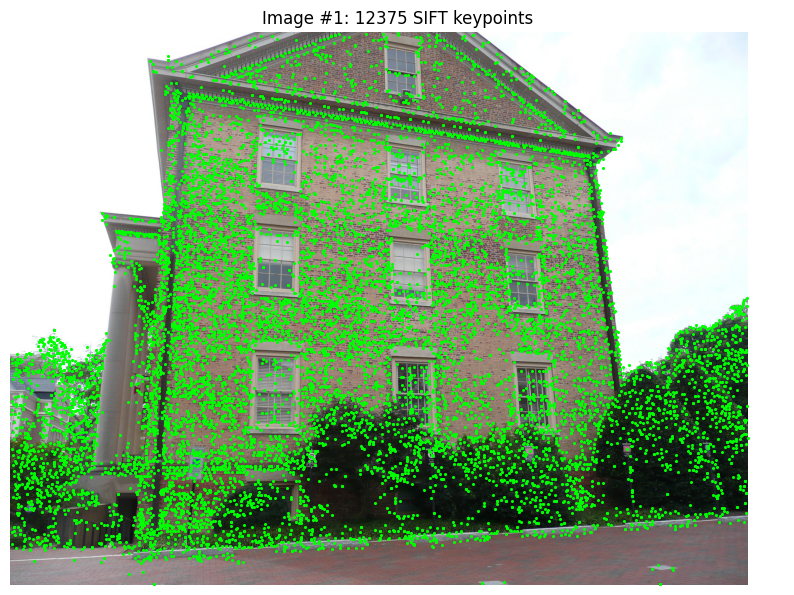

In [14]:
WS = "/content/runs/30_exhaustive_SIMPLE_PINHOLE"
names, order, kps, raw, ver = load_db(f"{WS}/database.db")

k = 1  # image number
iid = order[k-1]
plt.figure(figsize=(10, 7.5))
plt.imshow(img(30, names[iid]))
plt.scatter(*kps[iid].T, s=1.5, c="lime")
plt.title(f"Image #{k}: {len(kps[iid])} SIFT keypoints"); plt.axis("off")
print("Mean keypoints/image:", int(np.mean([len(v) for v in kps.values()])))

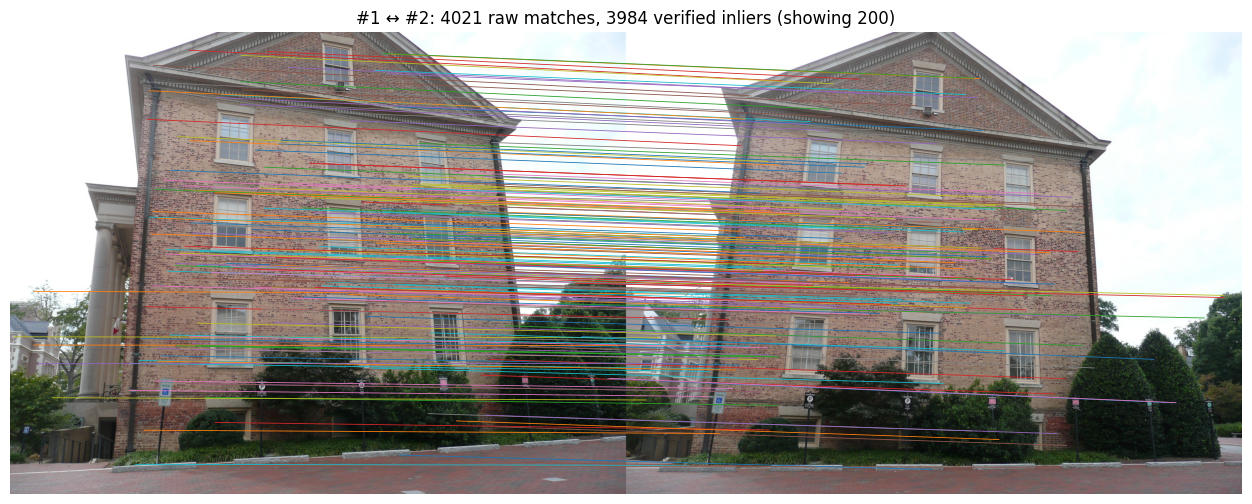

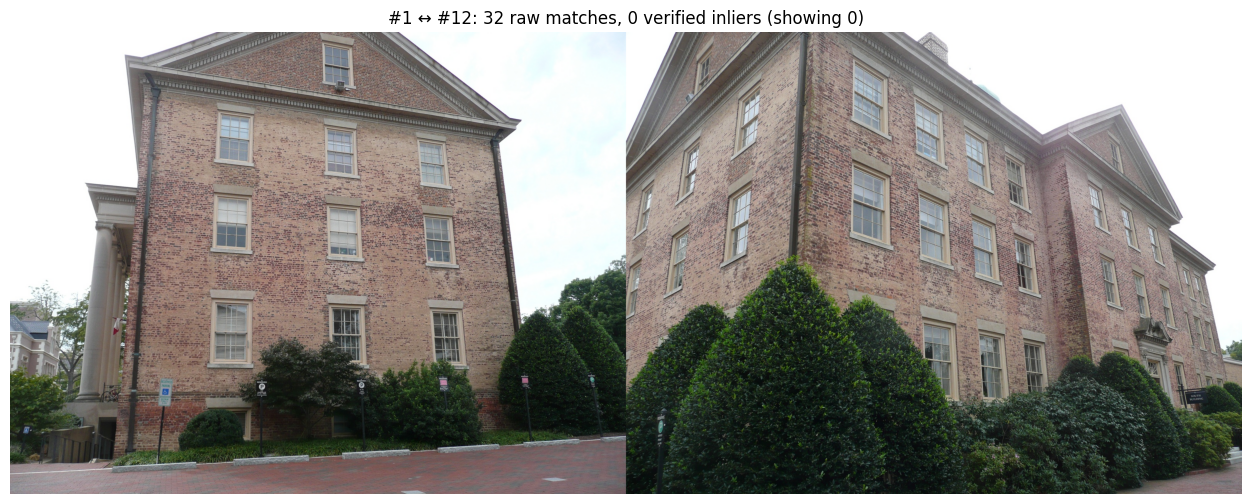

In [15]:
def show_matches(a, b, max_lines=200, seed=0):
    ia, ib = order[a-1], order[b-1]
    R, V = get_pair(raw, ia, ib), get_pair(ver, ia, ib)
    A, B = img(30, names[ia]), img(30, names[ib])
    canvas = np.hstack([A, B]); w = A.shape[1]
    sel = np.random.default_rng(seed).permutation(len(V))[:max_lines]
    plt.figure(figsize=(16, 6)); plt.imshow(canvas)
    for i, j in V[sel]:
        (x1, y1), (x2, y2) = kps[ia][i], kps[ib][j]
        plt.plot([x1, x2 + w], [y1, y2], lw=0.6)
    plt.title(f"#{a} ↔ #{b}: {len(R)} raw matches, {len(V)} verified inliers "
              f"(showing {min(max_lines, len(V))})"); plt.axis("off")

show_matches(1, 2)    # neighbours: many inliers
show_matches(1, 12)   # far apart: few or none

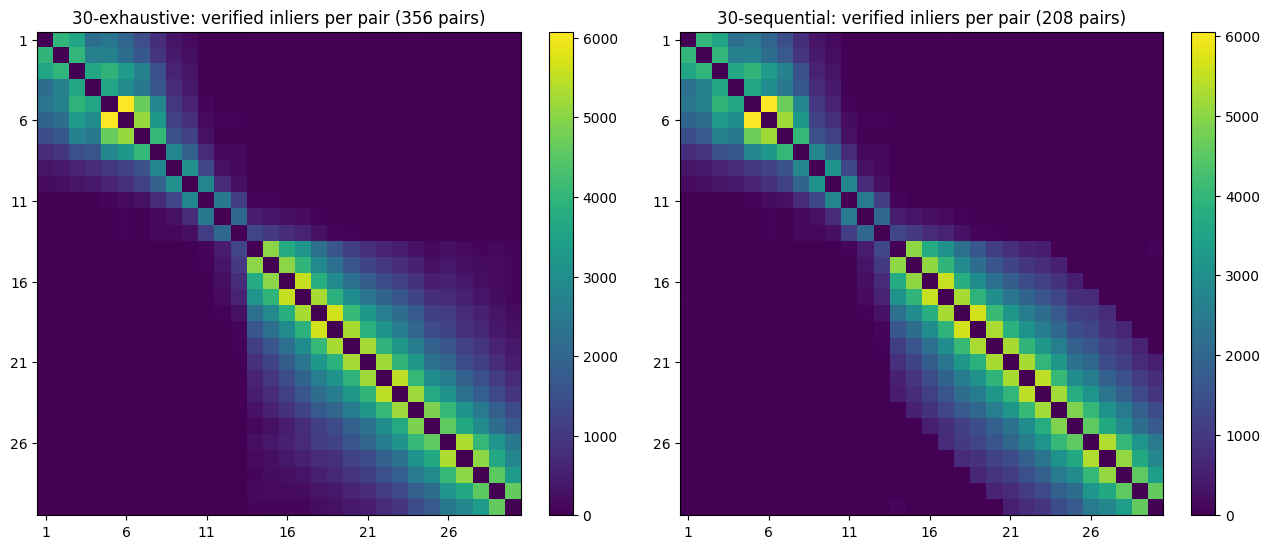

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, mode in zip(axes, ["exhaustive", "sequential"]):
    nm, od, _, _, vr = load_db(f"/content/runs/30_{mode}_SIMPLE_PINHOLE/database.db")
    N = len(od); pos = {iid: p for p, iid in enumerate(od)}
    Mtx = np.zeros((N, N))
    for (i1, i2), m in vr.items():
        Mtx[pos[i1], pos[i2]] = Mtx[pos[i2], pos[i1]] = len(m)
    im = ax.imshow(Mtx, cmap="viridis")
    ax.set_title(f"30-{mode}: verified inliers per pair ({len(vr)} pairs)")
    ax.set_xticks(range(0, N, 5), range(1, N+1, 5)); ax.set_yticks(range(0, N, 5), range(1, N+1, 5))
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()

In [17]:
from scipy.spatial.transform import Rotation as Rot
import plotly.graph_objects as go

def read_model(ws):
    txt = f"{ws}/sparse_txt"; os.makedirs(txt, exist_ok=True)
    sh(f"colmap model_converter --input_path {ws}/sparse/0 --output_path {txt} --output_type TXT")
    cam = [l.split() for l in open(f"{txt}/cameras.txt") if not l.startswith("#") and l.strip()][0]
    P = np.array([l.split()[:8] for l in open(f"{txt}/points3D.txt") if not l.startswith("#")], float)
    lines = [l for l in open(f"{txt}/images.txt") if not l.startswith("#")]
    C, D, U, N = [], [], [], []
    for l in lines[0::2]:                       # every other line: pose line (next is its 2D points)
        e = l.split()
        qw, qx, qy, qz = map(float, e[1:5]); t = np.array(e[5:8], float)
        R = Rot.from_quat([qx, qy, qz, qw]).as_matrix()   # COLMAP stores w first; scipy wants it last
        C.append(-R.T @ t)                      # camera centre in world coordinates
        D.append(R.T @ [0, 0, 1])               # viewing direction (camera +z)
        U.append(-R.T @ [0, 1, 0])              # camera "up" (camera +y points down)
        N.append(e[9])
    o = np.argsort(N)
    return cam, P, np.array(C)[o], np.array(D)[o], np.array(U)[o]

def clean(P, keep=98):
    d = np.linalg.norm(P[:, 1:4] - np.median(P[:, 1:4], 0), axis=1)
    return P[d < np.percentile(d, keep)]

for mode in ["15_exhaustive", "15_sequential", "30_sequential", "30_exhaustive"]:
    cam, *_ = read_model(f"/content/runs/{mode}_SIMPLE_PINHOLE")
    print(f"{mode:15s} f = {float(cam[4]):7.1f}px  cx = {float(cam[5]):.1f}  cy = {float(cam[6]):.1f}")

15_exhaustive   f =  1341.5px  cx = 800.0  cy = 600.0
15_sequential   f =  1342.2px  cx = 800.0  cy = 600.0
30_sequential   f =  1345.1px  cx = 800.0  cy = 600.0
30_exhaustive   f =  1345.1px  cx = 800.0  cy = 600.0


In [18]:
def plot3d(ws, title):
    cam, P, C, D, U = read_model(ws); P = clean(P)
    s = 0.06 * np.ptp(P[:, 1:4], 0).max()
    up = U.mean(0) / np.linalg.norm(U.mean(0))
    fig = go.Figure()
    fig.add_scatter3d(x=P[:, 1], y=P[:, 2], z=P[:, 3], mode="markers", name="3D points",
        marker=dict(size=1.2, color=[f"rgb({r:.0f},{g:.0f},{b:.0f})" for r, g, b in P[:, 4:7]]))
    fig.add_scatter3d(x=C[:, 0], y=C[:, 1], z=C[:, 2], mode="markers+text", name="cameras",
        text=[str(i + 1) for i in range(len(C))], marker=dict(size=3, color="red"))
    L = np.full((3 * len(C), 3), np.nan); L[0::3] = C; L[1::3] = C + s * D
    fig.add_scatter3d(x=L[:, 0], y=L[:, 1], z=L[:, 2], mode="lines", name="view dir",
        line=dict(color="red", width=3))
    fig.update_layout(title=f"{title} ({len(P)} pts shown, f={float(cam[4]):.0f}px)", height=700,
        scene=dict(aspectmode="data", camera=dict(up=dict(x=up[0], y=up[1], z=up[2]))))
    fig.show()

plot3d("/content/runs/30_sequential_SIMPLE_PINHOLE", "30-sequential sparse model")

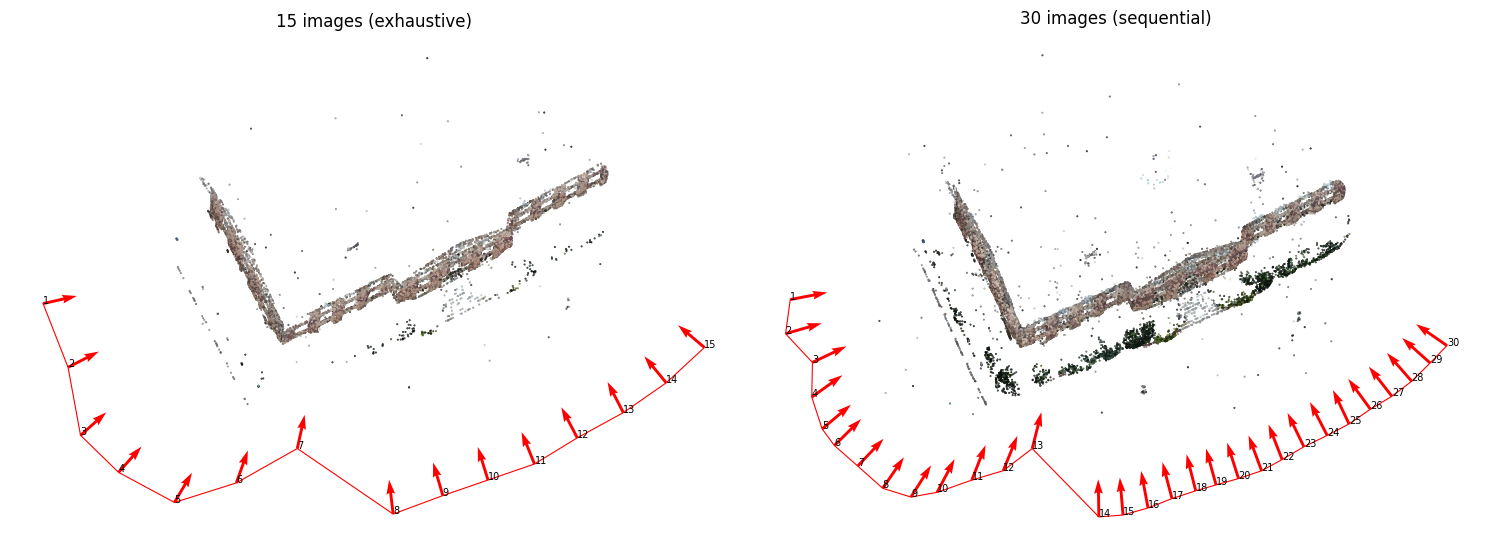

In [19]:
def topdown(ax, ws, title):
    cam, P, C, D, U = read_model(ws); P = clean(P)
    u = U.mean(0); u /= np.linalg.norm(u)
    c0 = C.mean(0)
    Cp = (C - c0) - np.outer((C - c0) @ u, u)            # camera centres flattened onto ground plane
    e1 = np.linalg.svd(Cp, full_matrices=False)[2][0]; e2 = np.cross(u, e1)
    to2d = lambda X: np.stack([(X - c0) @ e1, (X - c0) @ e2], 1)
    p2, c2 = to2d(P[:, 1:4]), to2d(C)
    d2 = np.stack([D @ e1, D @ e2], 1); d2 /= np.linalg.norm(d2, axis=1, keepdims=True)
    Lq = 0.08 * np.ptp(p2, 0).max()
    ax.scatter(*p2.T, s=0.2, c=P[:, 4:7] / 255)
    ax.plot(*c2.T, "r-", lw=0.8)
    ax.quiver(*c2.T, *(d2 * Lq).T, color="red", angles="xy", scale_units="xy", scale=1, width=0.004)
    for i, (x, y) in enumerate(c2): ax.annotate(str(i + 1), (x, y), fontsize=7)
    ax.set_aspect("equal"); ax.set_title(title); ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
topdown(axes[0], "/content/runs/15_exhaustive_SIMPLE_PINHOLE", "15 images (exhaustive)")
topdown(axes[1], "/content/runs/30_sequential_SIMPLE_PINHOLE", "30 images (sequential)")
plt.tight_layout(); plt.savefig(f"{SAVE}/topdown_15_vs_30.png", dpi=200)